# The site-held-out protocol with a pre-declared criterion: what a campaign held out reveals that a random split hides

**Question:** Does any predictor clear the pre-declared criterion when whole campaigns are held out?

**Level 4: Beyond the state of the art** · Needs: 04-benchmark-protocol/02-scores-the-null-and-the-interval, 04-benchmark-protocol/03-placing-a-published-score-in-its-own-protocol · Reading time: about 45 minutes

## Objectives

Claim BS-1 of the product is a protocol and not a model: the learned tier is judged with whole campaigns held out, with intervals that resample campaigns, and against a criterion written down before the run. This notebook runs that protocol on every predictor of the ladder and asks the question the criterion exists to answer.

By the end you will have:

- refitted gradient boosting fold by fold and read the error of each held-out campaign;
- run the eleven predictors of the ladder and the null under the protocol and measured what it costs each one against a random split;
- drawn the interval of every predictor, resampling campaigns, as a forest plot on both row sets;
- applied the criterion, word for word, to the best learned predictor on 97 and on 91 blasts, and compared everything with what the offline bake committed.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

One cell does all the preparation: it imports the packages, prints their installed versions so the output records which engine produced every number below, defines the table helper and loads the 97 training blasts.

In [1]:
# Imports, the versions behind every number below, a small table helper and the corpus
import json
from importlib.metadata import version
from pathlib import Path
import hashlib
import textwrap

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas is not part of the notebook environment, so a table is a plain HTML table
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


BENCHMARK = Path("../../../data/derived/benchmark.json")
train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The committed benchmark, read once for the check at the end | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json` |

Every score, interval and gap that the notebook discusses is recomputed by refitting the predictors on the corpus; the committed benchmark appears only in the last step.

## Method

The protocol has four parts, and each is a decision that a cell below carries out.

1. **Hold out the campaign.** One fold per campaign, the other nine in training, the null refitted in every fold.
2. **Report the gap.** For every predictor, the median score of 100 random 80/20 draws minus its pooled held-out score, so the cost of the protocol is a number and not an impression.
3. **Resample the right unit.** Intervals draw campaigns, not blasts, 2000 times.
4. **Declare the criterion first.** The sentence that decides whether the learned tier generalises is fixed before the run, and its hash is pinned in the engine's tests.

The score is `r2_identity` throughout. What to look for in the first two steps: which campaigns the held-out predictor gets wrong, in which direction, and how wide an honest interval is for the pooled score.

### Step 1: gradient boosting, fold by fold

The cell refits gradient boosting and the null on nine campaigns for each of the ten folds, predicts the tenth, and keeps the out-of-fold predictions. The table gives, for each campaign, the mean measured size, the mean predicted size, the bias and the root-mean-square error of that fold: it is where the pooled score comes from.

In [2]:
# Gradient boosting refitted fold by fold with the campaign held out, and the null refitted beside it
factories = bf.default_arms()
folds = list(bf.leave_one_site_out(train))
tested, boosted, null = [], [], []
rows, campaign_means = [], {}
for fold in folds:
    out = factories["xgboost"]().fit(fold.train).predict(fold.test)
    tested += list(fold.test)
    boosted += out
    null += factories["null"]().fit(fold.train).predict(fold.test)
    measured = np.mean([blast.x50_m for blast in fold.test])
    predicted = np.mean([p.x50_m for p in out])
    site = fold.detail["held_out_site"]
    campaign_means[site] = (measured, predicted)
    error = bf.score(fold.test, out).rmse_m
    sizes = (len(fold.train), len(fold.test))
    means = [f"{value:.3f}" for value in (measured, predicted)]
    rows.append((site, *sizes, *means, f"{predicted - measured:+.3f}", f"{error:.3f}"))
show_table(["held-out campaign", "training", "test",
            "mean measured (m)", "mean predicted (m)",
            "bias (m)", "RMSE (m)"], rows)

held-out campaign,training,test,mean measured (m),mean predicted (m),bias (m),RMSE (m)
Akdaglar,75,22,0.171,0.245,+0.074,0.088
Dongri-Buzurg,88,9,0.413,0.260,-0.153,0.225
Enusa,85,12,0.396,0.463,+0.067,0.114
Miami,91,6,0.080,0.378,+0.298,0.300
Mrica,86,11,0.166,0.257,+0.090,0.100
Murgul,90,7,0.311,0.672,+0.360,0.365
Ozmert,90,7,0.191,0.167,-0.024,0.089
Reocin,87,10,0.616,0.382,-0.234,0.314
Reocin-UG,91,6,0.593,0.553,-0.040,0.080
Soma,90,7,0.224,0.126,-0.099,0.106


The error is concentrated. The smallest fold errors are Reocin-UG at 0.080 m, Ozmert at 0.089 m and Akdaglar at 0.088 m, the last with the 22 blasts that make it the largest campaign, while Murgul at 0.365 m, Miami at 0.300 m and Reocin at 0.314 m are several times larger. The biases have a pattern: the finest campaign, Miami, is predicted at 0.378 m against a measured 0.080 m (+0.298), and the coarsest, Reocin, at 0.382 m against 0.616 m (-0.234), so the model pulls a campaign toward the middle of the corpus; Murgul breaks the pattern, a mid-sized campaign predicted at 0.672 m against 0.311 m (+0.360). The table does not say why Murgul fails, only that a model trained on the other nine campaigns has nothing that resembles it.

### Step 2: the pooled score and the honest interval

The ten folds are pooled into 97 out-of-fold predictions and scored once. The interval is the 95 percent bootstrap that resamples whole campaigns, with 2000 draws and a fixed seed, the unit that is independent under this protocol.

In [3]:
# Pool the ten folds, score gradient boosting and the null, and draw the interval that resamples campaigns
boosted_score = bf.score(tested, boosted)
null_score = bf.score(tested, null)
point, low, high = bf.bootstrap_interval(tested, boosted, "r2_identity", n_boot=2000, unit="site", seed=0)
interval = f"{low:.3f} to {high:.3f}"
rows = []
for label, score, ends in (("gradient boosting", boosted_score, interval),
                           ("null (training mean)", null_score, "-")):
    rows.append((label, f"{score.r2_identity:.4f}", f"{score.rmse_m:.4f}", ends))
show_table(["predictor", "r2_identity", "RMSE (m)",
            "95 % interval, campaigns resampled"], rows)
print(f"blasts scored: {len(tested)} | campaigns: {len(folds)} | interval draws: 2000")

predictor,r2_identity,RMSE (m),"95 % interval, campaigns resampled"
gradient boosting,-0.0342,0.1906,-2.232 to 0.418
null (training mean),-0.2163,0.2067,-


blasts scored: 97 | campaigns: 10 | interval draws: 2000


Pooled over the 97 blasts, gradient boosting scores -0.0342 and the null -0.2163, with root-mean-square errors of 0.1906 m and 0.2067 m. A constant equal to the overall mean of the measurements would score exactly zero, so the model is slightly worse than that constant, and it is ahead of the null only because the null is itself pulled the wrong way by the training mean. The campaign interval runs from -2.232 to 0.418 and holds zero with room to spare. The cell does not say the model is useless: it says that with ten campaigns the evidence cannot tell this model from a constant.

## State of the art

- The learned predictors published on this corpus (Sui et al. 2025, https://doi.org/10.3390/app15031254) report a score from one random 80/20 split.
- The SDD research basis notes that the abstracts of the learned-predictor studies (Chen et al. 2025, https://doi.org/10.1007/s00521-025-11321-3; Gebretsadik et al. 2024, https://doi.org/10.1007/s42452-024-05888-0) do not say that a whole mine was held out, and that the published predictors are single-site.
- Grouped resampling is the established remedy when data are dependent (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

The previous notebook ran the first of these on the engine and found that its 0.943 is not a typical draw of its own protocol. What the literature does not offer is a way to say whether a learned predictor transfers to a campaign it has not seen, with an uncertainty that counts campaigns and a verdict whose wording cannot be adjusted afterwards. That is the gap the next section fills.

## Beyond the state of the art

Claim BS-1 is evidence of four things at once: the cost of the practitioner's question as a number, an interval that does not overstate it, a per-campaign account of where predictors fail, and a verdict fixed in advance. The steps below produce each from a run of the whole ladder: the classical, statistical and learned predictors, and the null, all with the campaign held out.

### Step 3: the whole ladder, each campaign held out

The cell repeats the ten folds for every predictor of the ladder but the oracle, which sees the answer, and the group discriminant, which abstains on every blast. The table gives each predictor's tier, how many blasts it scored and how many it declined to answer, and its pooled score on whatever it answered.

In [4]:
# Every predictor of the ladder, each campaign held out in turn
ladder = [name for name in factories if name not in ("oracle", "group-discriminant")]
tiers = {name: factories[name]().tier for name in ladder}
held = {name: [] for name in ladder}
for fold in folds:
    for name in ladder:
        held[name] += factories[name]().fit(fold.train).predict(fold.test)
rows = []
for name in ladder:
    score = bf.score(tested, held[name])
    rows.append((name, tiers[name], score.n_scored, score.n_abstained, f"{score.r2_identity:.4f}"))
show_table(["predictor", "tier", "blasts scored", "abstentions", "r2_identity"], rows)

predictor,tier,blasts scored,abstentions,r2_identity
null,control,97,0,-0.2163
kuznetsov,classical,91,6,0.3112
kuznetsov-transfer,classical,91,6,0.2982
kuznetsov-capped,classical,91,6,0.3523
published-regression,statistical,97,0,0.8018
refitted-regression,statistical,93,4,-4.0746
published-neural-net,learned,97,0,-0.6256
svr-rbf,learned,96,1,-0.3868
svr-poly,learned,86,11,-4.5457
random-forest,learned,97,0,-0.2315


The ladder splits into three groups. Every learned predictor is below zero: -0.0342 for gradient boosting, -0.0345 for stacking, -0.2315 for the random forest, -0.3868 for the support vector regression with the radial kernel, -0.6256 for the published network and -4.5457 for the polynomial-kernel one, which also declines 11 blasts. The three classical variants score 0.3112, 0.2982 and 0.3523 on the 91 blasts they answer, and abstain on 6. The published regression scores 0.8018, but its source fitted it on all 97 of these blasts, so no split hides a blast from it. The table does not say the classical equation transfers freely: two of its variants use a per-campaign constant, and only `kuznetsov-transfer`, at 0.2982, uses nothing from the target campaign.

### Step 4: what the protocol costs

For each predictor the cell draws the 100 random 80/20 splits of the second step of the previous notebook, takes the median score, and subtracts the held-out score. The published neural network is left out of the random draws because 100 refits of it take about three minutes; its held-out score is in every other table.

In [5]:
# The median over 100 random draws for each predictor, and the gap to its held-out score
random_draws = bf.repeated_random_splits(train, n_repeats=100, seed=0)
skipped = "published-neural-net"  # 100 refits take about three minutes
random_median = {}
for name in ladder:
    if name == skipped:
        continue
    values = []
    for draw in random_draws:
        model = factories[name]().fit(draw.train)
        values.append(bf.score(draw.test, model.predict(draw.test)).r2_identity)
    random_median[name] = np.median([v for v in values if v is not None])
held_score = {name: bf.score(tested, held[name]).r2_identity for name in ladder}
gap = {name: random_median[name] - held_score[name] for name in random_median}
rows = []
for name in sorted(gap, key=gap.get, reverse=True):
    rows.append((name, tiers[name], f"{random_median[name]:.3f}", f"{held_score[name]:.3f}", f"{gap[name]:.3f}"))
show_table(["predictor", "tier", "random median",
            "held out", "gap"], rows)
learned = [name for name in gap if tiers[name] == "learned"]
median_gap = np.median([gap[name] for name in learned])
print(f"median gap, learned predictors run ({len(learned)}): {median_gap:.3f}")

predictor,tier,random median,held out,gap
svr-poly,learned,0.395,-4.546,4.940
refitted-regression,statistical,0.686,-4.075,4.760
svr-rbf,learned,0.665,-0.387,1.052
random-forest,learned,0.749,-0.231,0.981
xgboost,learned,0.704,-0.034,0.738
stacking,learned,0.703,-0.035,0.738
null,control,-0.036,-0.216,0.180
kuznetsov-capped,classical,0.399,0.352,0.047
kuznetsov-transfer,classical,0.312,0.298,0.014
published-regression,statistical,0.805,0.802,0.003


median gap, learned predictors run (5): 0.981


For the five learned predictors run, the gap runs from 0.738 for gradient boosting and stacking to 4.940 for the polynomial-kernel regression, with a median of 0.981, and their random medians lie between 0.665 and 0.749 except the polynomial one at 0.395. The classical variants lose almost nothing, 0.047, 0.014 and -0.009, and so does the published regression at 0.003, which has nothing to lose since it was fitted on every blast. The network is absent from this table by choice, not by omission. The table does not say the random median is a fair score, only that the protocol is what moves it.

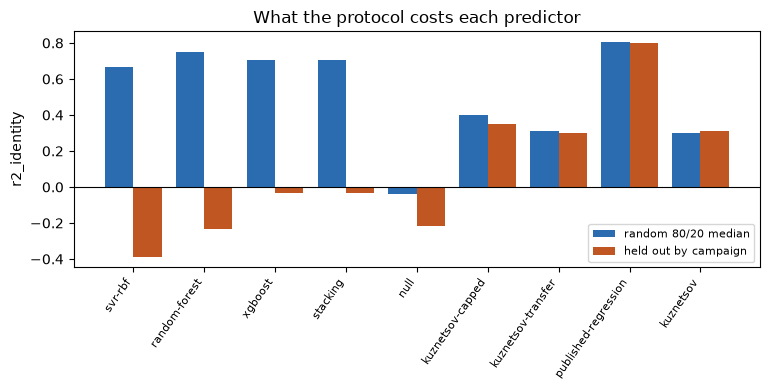

left out of the figure, held-out score below -1: ['refitted-regression', 'svr-poly']


In [6]:
# The gap as a figure: random median against held-out score, one pair of bars per predictor
shown = [name for name in sorted(gap, key=gap.get, reverse=True) if held_score[name] > -1]
fig, ax = plt.subplots(figsize=(7.8, 4.0))
position = np.arange(len(shown))
ax.bar(position - 0.2, [random_median[n] for n in shown], 0.4, color="#2b6cb0",
       label="random 80/20 median")
ax.bar(position + 0.2, [held_score[n] for n in shown], 0.4, color="#c05621",
       label="held out by campaign")
ax.set_xticks(position, shown, rotation=55, ha="right", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("r2_identity")
ax.set_title("What the protocol costs each predictor")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("left out of the figure, held-out score below -1:", [n for n in gap if n not in shown])

Each blue bar is what a random 80/20 split reports and each orange bar what the same predictor scores with the campaign held out. For the learned predictors the blue bars stand between 0.665 and 0.749 and the orange bars fall to or below zero, while for the classical variants and the published regression the two bars have almost the same height. The two predictors whose held-out score is below -1, the refitted regression and the polynomial-kernel regression, are left out of the plot so the others remain readable, and the cell prints their names. The figure shows what the protocol costs; it does not show whether the random-split number was ever a fair estimate for a new mine.

### Step 5: the intervals that resample campaigns

For every predictor and for each of the two row sets, `all` (97 blasts) and `geometry` (the 91 blasts on which the classical equation can answer), the cell computes the 95 percent interval with 2000 campaign resamples. It lists the ends and flags the predictors whose lower end is above zero, and the predictor that was fitted by its source on these very blasts, for which no split can hide a blast.

In [7]:
# The interval of every predictor, resampling campaigns, on both row sets
intervals = {}
for name in ladder:
    for support, keep in bf.SUPPORTS.items():
        kept = [i for i, blast in enumerate(tested) if keep(blast)]
        chosen = [tested[i] for i in kept]
        chosen_predictions = [held[name][i] for i in kept]
        intervals[name, support] = bf.bootstrap_interval(
            chosen, chosen_predictions, "r2_identity", n_boot=2000, unit="site", seed=0)
in_sample = [name for name in ladder if factories[name]().in_sample_corpus]
rows = []
for name in ladder:
    if name == "null":
        continue
    ends = [f"{intervals[name, s][1]:.2f} to {intervals[name, s][2]:.2f}" for s in bf.SUPPORTS]
    above = [s for s in bf.SUPPORTS if intervals[name, s][1] > 0]
    rows.append((name, tiers[name], *ends, ", ".join(above) or "-", "yes" if name in in_sample else ""))
show_table(["predictor", "tier", "all 97", "geometry 91",
            "lower end above zero",
            "fitted on these blasts"], rows)

predictor,tier,all 97,geometry 91,lower end above zero,fitted on these blasts
kuznetsov,classical,-0.96 to 0.70,-0.97 to 0.69,-,
kuznetsov-transfer,classical,-1.10 to 0.72,-1.10 to 0.71,-,
kuznetsov-capped,classical,-0.95 to 0.74,-0.96 to 0.73,-,
published-regression,statistical,0.57 to 0.90,0.50 to 0.88,"all, geometry",yes
refitted-regression,statistical,-19.48 to 0.02,-21.92 to 0.09,-,
published-neural-net,learned,-3.35 to 0.01,-3.42 to 0.09,-,
svr-rbf,learned,-1.61 to -0.06,-1.86 to -0.07,-,
svr-poly,learned,-16.24 to -0.83,-17.18 to -0.95,-,
random-forest,learned,-2.78 to 0.38,-2.88 to 0.40,-,
xgboost,learned,-2.23 to 0.42,-1.78 to 0.53,-,


With campaigns resampled, no learned predictor has an interval whose lower end is above zero on either row set. Gradient boosting runs from -2.23 to 0.42 on 97 blasts and -1.78 to 0.53 on 91, stacking from -2.25 to 0.42 and -1.81 to 0.54, and the published network from -3.35 to 0.01 and -3.42 to 0.09. The two support vector regressions lie wholly below zero: -1.61 to -0.06 for the radial kernel and -16.24 to -0.83 for the polynomial one. The classical variants span zero as well (-0.96 to 0.70 for the base equation). The only interval above zero, 0.57 to 0.90, belongs to the published regression, which the last column marks as fitted on these blasts. The table does not say the classical or learned predictors have no skill, only that ten campaigns cannot show it.

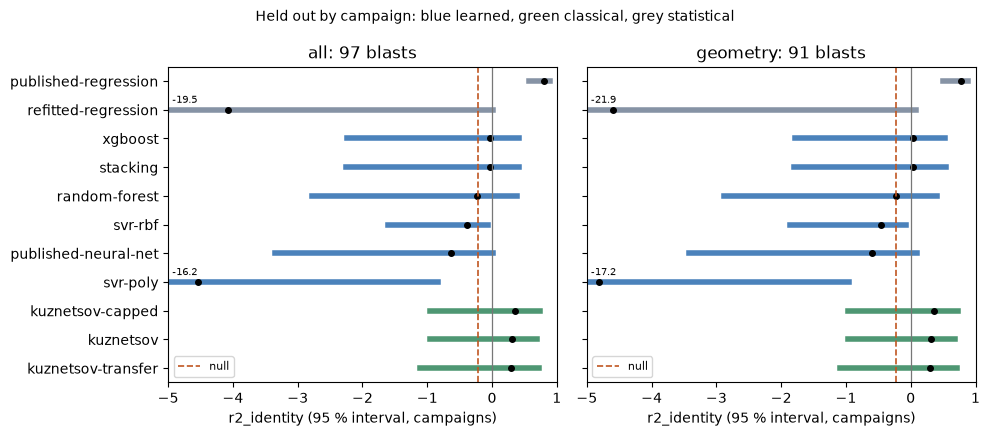

In [8]:
# The forest plot: every predictor's interval, both row sets, the null as a reference line
colors = {"classical": "#2f855a", "statistical": "#718096", "learned": "#2b6cb0"}
names = sorted((n for n in ladder if n != "null"), key=lambda n: (tiers[n], intervals[n, "all"][0]))
floor = -5.0
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.4), sharey=True)
for ax, support in zip(axes, bf.SUPPORTS):
    for row, name in enumerate(names):
        point, low, high = intervals[name, support]
        ax.plot([max(low, floor), high], [row, row], lw=4, color=colors[tiers[name]], alpha=0.85)
        ax.plot([point], [row], "o", color="black", ms=4)
        if low < floor:
            ax.annotate(f"{low:.1f}", (floor, row), xytext=(3, 5), textcoords="offset points", fontsize=7)
    ax.axvline(0, color="#777", lw=0.9)
    ax.axvline(intervals["null", support][0], color="#c05621", lw=1.2, ls="--", label="null")
    ax.set_xlim(floor, 1.0)
    ax.set_xlabel("r2_identity (95 % interval, campaigns)")
    ax.set_title(f"{support}: {len([b for b in tested if bf.SUPPORTS[support](b)])} blasts")
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_yticks(range(len(names)), names)
fig.suptitle("Held out by campaign: blue learned, green classical, grey statistical", fontsize=10)
fig.tight_layout()
plt.show()

The forest plot makes the table visible: every blue interval crosses zero except the two support vector regressions, whose intervals lie to its left, and the dashed line of the null, at -0.2163 on 97 blasts, falls inside almost every interval, so most predictors cannot be separated from it. The grey interval of the published regression is the lone one to the right of zero. The refitted regression and the polynomial support vector regression are cut at -5 and labelled with their true lower ends, -19.5 and -16.2. The two panels are almost the same, so dropping the six Miami blasts does not change the picture. The figure shows overlap between intervals, not the size of any difference, and a wide interval means the data are uninformative, not that the model is bad.

### Step 6: the criterion, applied

The cell prints the criterion exactly as the engine holds it, with the first characters of its hash, then applies both halves to the best learned predictor on each row set: the score must be above zero, and at least 0.10 above the null's. It also names the campaign that separates the two row sets.

In [9]:
# The pre-declared criterion, verbatim, then applied to the best learned predictor on each row set
print(textwrap.fill(bf.KILL_CRITERION, 110))
print("sha256, first 12 characters:", hashlib.sha256(bf.KILL_CRITERION.encode()).hexdigest()[:12])
learned = [name for name in ladder if tiers[name] == "learned"]
rows = []
for support, keep in bf.SUPPORTS.items():
    kept = [i for i, blast in enumerate(tested) if keep(blast)]
    r2 = {n: bf.score([tested[i] for i in kept], [held[n][i] for i in kept]).r2_identity for n in [*learned, "null"]}
    best = max(learned, key=r2.get)
    margin = r2[best] - r2["null"]
    met = r2[best] > 0 and margin >= 0.10
    low, high = intervals[best, support][1:]
    values = [f"{r2[best]:.4f}", f"{r2['null']:.4f}", f"{margin:.4f}"]
    rows.append((support, len(kept), best, *values, r2[best] > 0, margin >= 0.10, met, f"{low:.2f} to {high:.2f}"))
show_table(["rows", "n", "best learned", "r2_identity", "null", "margin",
            "> 0", ">= 0.10", "criterion met", "95 % interval"], rows)
outside = sorted({blast.site for blast in train if not bf.has_absolute_geometry(blast)})
print("campaigns outside the geometry row set:", outside)

The learned tier counts as generalising across sites only if the best learned arm's variance explained under
leave-one-site-out is BOTH positive and at least 0.10 above the null model's. Both halves are required: a
margin over a null that is itself deeply negative is not skill, it is two models failing by different amounts.
sha256, first 12 characters: a13f11385ef8


rows,n,best learned,r2_identity,null,margin,> 0,>= 0.10,criterion met,95 % interval
all,97,xgboost,-0.0342,-0.2163,0.1821,False,True,False,-2.23 to 0.42
geometry,91,stacking,0.0343,-0.2320,0.2663,True,True,True,-1.81 to 0.54


campaigns outside the geometry row set: ['Miami']


Applied to the letter, the criterion gives two answers. On all 97 blasts the best learned predictor is gradient boosting at -0.0342, which clears the margin, 0.1821 above a null at -0.2163, but is not positive, so the criterion is not met. On the 91 blasts with a geometry the best is stacking at 0.0343, which is positive and 0.2663 above a null at -0.2320, so the criterion is met. The campaign that separates the two sets is Miami, which publishes no hole diameter, and the verdict depends on whether its six blasts are counted. The margin half passes on both sets because the null is deeply negative, which is exactly the case the second half of the sentence guards against. The table does not say that stacking at 0.0343 has skill: its interval on that row set, -1.81 to 0.54, holds zero.

### Step 7: where the held-out predictor fails

A pooled score hides which campaigns are wrong. The cell plots, for each campaign, the mean size gradient boosting predicted when it was held out against the mean size measured, using the numbers of the first step.

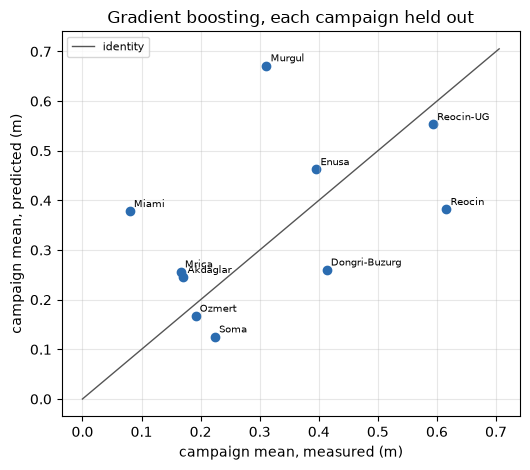

In [10]:
# Where the held-out gradient boosting fails: predicted against measured campaign mean
sites = list(campaign_means)
measured_means = [campaign_means[site][0] for site in sites]
predicted_means = [campaign_means[site][1] for site in sites]
fig, ax = plt.subplots(figsize=(5.4, 4.8))
ax.scatter(measured_means, predicted_means, color="#2b6cb0")
for site, x, y in zip(sites, measured_means, predicted_means):
    ax.annotate(site, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
limit = max(measured_means + predicted_means) * 1.05
ax.plot([0, limit], [0, limit], color="#555", lw=1, label="identity")
ax.set_xlabel("campaign mean, measured (m)")
ax.set_ylabel("campaign mean, predicted (m)")
ax.set_title("Gradient boosting, each campaign held out")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Points on the line would be campaigns predicted right. Miami at a measured 0.080 m and Murgul at 0.311 m lie well above it, predicted at 0.378 m and 0.672 m, while Reocin at 0.616 m and Dongri-Buzurg at 0.413 m lie below, predicted at 0.382 m and 0.260 m, and the large campaigns Akdaglar, Mrica and Enusa lie close to it. The predictions only span 0.126 m to 0.672 m although the measured campaign means span 0.080 m to 0.616 m, so the model compresses the campaigns toward a middle value, which is why the margin over a null that moves the other way is easy to obtain. The figure shows campaign means and hides the blasts inside each campaign, so it cannot say how the error splits within one.

### Check against the committed benchmark

The only comparison with a committed artifact in this notebook: the scores, the interval ends and the protocol gaps computed here are set against the ones the offline bake wrote into `benchmark.json`, together with the text of the criterion.

In [11]:
# Check: scores, intervals and verdict equal what the offline bake committed
committed = json.loads(BENCHMARK.read_text(encoding="utf-8"))
loso = committed["protocols"]["leave-one-site-out"]["arms"]
verdict = committed["verdict"]
score_gap = max(abs(held_score[n] - loso[n]["r2_identity"]) for n in ladder)
interval_gap = 0.0
for name, both in verdict["intervals_95"].items():
    for support, ends in both.items():
        if ends:
            low, high = intervals[name, support][1:]
            interval_gap = max(interval_gap, abs(low - ends[0]), abs(high - ends[1]))
gaps = verdict["protocol_gap_random_minus_grouped"]
gap_gap = max(abs(gap[n] - gaps[n]) for n in gaps if n in gap)
print(f"largest difference, held-out scores: {score_gap:.1e}")
print(f"largest difference, interval ends: {interval_gap:.1e}")
print(f"largest difference, protocol gaps: {gap_gap:.1e}")
print("same criterion text:", bf.KILL_CRITERION == committed["kill_criterion"])

largest difference, held-out scores: 0.0e+00
largest difference, interval ends: 0.0e+00
largest difference, protocol gaps: 0.0e+00
same criterion text: True


## Results

**Answer:** by the letter of the criterion, on 97 blasts no predictor clears it and on 91 one does, and in neither case does the evidence separate a learned predictor from a constant. On all 97 blasts the best learned predictor is gradient boosting at -0.0342, which is not positive, although it is 0.1821 above the null; on the 91 blasts with a geometry it is stacking at 0.0343, 0.2663 above the null, and the criterion is met. No learned predictor has a campaign interval whose lower end is above zero (gradient boosting -2.23 to 0.42, stacking -1.81 to 0.54 on 91), and the only interval above zero, 0.57 to 0.90, belongs to the published regression that its source fitted on these blasts. The protocol costs the five learned predictors run a median gap of 0.981 between the random-split median and the held-out score, against -0.009 to 0.047 for the classical variants. Murgul is over-predicted by 0.360 m, Miami by 0.298 m and Reocin under-predicted by 0.234 m. All scores, interval ends and gaps equal the committed benchmark, with a largest difference of 0.0e+00.

**What this does not show.** Meeting the criterion on 91 blasts does not make the learned predictors good: the point score is 0.0343 and its interval holds zero, so the criterion is a minimum for generalising, not a certificate of skill. The published network is absent from the gap table because its random draws take three minutes, and the classical equation's constants are not blind to the campaign. With ten campaigns no analysis here can say whether more campaigns would change the verdict, and the verdict depends on whether Miami's six blasts are counted.

## Summary

- The protocol makes the cost of the practitioner's question a number: the learned predictors lose a median 0.981 against a random split, the classical variants almost nothing (claim BS-1).
- Intervals that resample campaigns leave no learned predictor above zero; the only interval above zero is the published regression, fitted on these blasts.
- The criterion, fixed by a hash, is not met on 97 blasts (gradient boosting, -0.0342) and met on 91 (stacking, 0.0343); the verdict is reported on both row sets.
- Next: topic 05 opens the learned predictors themselves and why each declines where it does.

## References

- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (the random-split protocol)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (grouped resampling under dependence)
- Chen et al. 2025, https://doi.org/10.1007/s00521-025-11321-3 (learned predictors, abstract only)
- Gebretsadik et al. 2024, https://doi.org/10.1007/s42452-024-05888-0 (learned predictors, abstract only)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `docs/protocols/04_criterion-and-row-sets.md` of this repository, for the criterion's wording, its hash and its history
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/